# So sánh K-Means và DBSCAN trên lượt đón Uber NYC

**Câu hỏi:** Với cùng lượt đón đã lọc, hai thuật toán chia không gian khác nhau thế nào? K-Means luôn gán mỗi điểm vào một trong `k` cụm; DBSCAN tìm vùng đủ dày và có thể để một điểm ở trạng thái nhiễu.

Notebook này là **thí nghiệm offline** để so sánh thuật toán, không thay đổi thuật toán hay kết quả của ứng dụng. Dữ liệu là lượt đón lịch sử năm 2014, không phải nhu cầu theo thời gian thực.

**Thiết kế so sánh:**

1. Dùng `data/processed/full.parquet` và chính hàm `filter_context` của ứng dụng để lấy **cùng một tập điểm**.
2. Chạy cả hai trên tọa độ `(x_m, y_m)` tính bằng **mét**, không chuẩn hóa z-score và không lấy mẫu trước khi phân cụm.
3. K-Means được chạy với `k` bằng số cụm DBSCAN tìm được để kiểm soát số cụm. Lần chạy `k=5` chỉ giúp minh họa cách K-Means chia thành năm vùng lớn; không dùng để kết luận thuật toán nào tốt hơn.
4. So sánh số cụm, phần điểm được gán, tỷ lệ nhiễu, kích thước cụm và hình dạng phân bố. Không dùng riêng số cụm hay tỷ lệ nhiễu làm thước đo chất lượng.

In [15]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "hotspot").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src" / "hotspot").is_dir():
    raise FileNotFoundError("Hãy chạy notebook trong repository chứa src/hotspot.")
sys.path.insert(0, str(ROOT / "src"))

from hotspot.dbscan import run_dbscan
from hotspot.filters import SpatialSelection, filter_context

SEED = 42
AREA = "Manhattan"
WEEKDAYS = ["Friday"]
START_MINUTE = 18 * 60
WINDOW_MINUTES = 60
MAX_MATCHING_DATES = 5
EPS_M = 70
MIN_SAMPLES = 15
K_OVERVIEW = 5

print("Repository:", ROOT)
print(f"Ngữ cảnh: {AREA}, {WEEKDAYS}, 18:00–19:00, {MAX_MATCHING_DATES} ngày phù hợp gần nhất")

Repository: /Users/hongphuc/workspace/CS313/Density-based Method
Ngữ cảnh: Manhattan, ['Friday'], 18:00–19:00, 5 ngày phù hợp gần nhất


## 1. Lấy cùng tập lượt đón

Chỉ đọc các cột cần thiết để giảm bộ nhớ. Đổi tên cột trong bộ nhớ theo contract của `filter_context`; file dữ liệu và API không bị sửa. `max_matching_dates=5` chọn năm ngày Thứ Sáu gần nhất **có trong toàn bộ dữ liệu**, đúng logic ứng dụng.

In [16]:
path = ROOT / "data" / "processed" / "full.parquet"
if not path.is_file():
    raise FileNotFoundError(f"Không thấy {path}. Xem README để chuẩn bị dữ liệu trước khi chạy notebook.")

pickups = pd.read_parquet(
    path,
    columns=["pickup_time", "lat", "lon", "borough", "x_m", "y_m"],
).rename(columns={
    "pickup_time": "pickup_datetime",
    "lat": "latitude",
    "lon": "longitude",
    "borough": "area",
})
filtered, n_dates = filter_context(
    pickups,
    spatial_selection=SpatialSelection.for_borough(AREA),
    weekday_selection=WEEKDAYS,
    start_minute=START_MINUTE,
    window_minutes=WINDOW_MINUTES,
    max_matching_dates=MAX_MATCHING_DATES,
    max_points=200_000,
)
del pickups
if len(filtered) < 3:
    raise ValueError("Quá ít điểm để so sánh; hãy chọn khu vực hoặc khung giờ khác.")
xy = filtered[["x_m", "y_m"]].to_numpy(dtype="float64")
print(f"{len(filtered):,} lượt đón trên {n_dates} ngày phù hợp; khoảng {filtered['pickup_datetime'].min()} đến {filtered['pickup_datetime'].max()}")
print("Tọa độ đầu vào:", xy.shape, "đơn vị mét")

10,910 lượt đón trên 5 ngày phù hợp; khoảng 2014-08-29 18:00:00 đến 2014-09-26 18:59:00
Tọa độ đầu vào: (10910, 2) đơn vị mét


## 2. Chạy DBSCAN như ứng dụng

`eps=70 m` và `min_samples=15` là giá trị mặc định trên giao diện hiện tại. `-1` là điểm nhiễu. Hàm `run_dbscan` chỉ dùng tọa độ mét và không lấy mẫu khi `point_cap=None`.

In [17]:
db = run_dbscan(filtered, eps_m=EPS_M, min_samples=MIN_SAMPLES)
db_labels = db.labels
n_db = db.n_clusters
if n_db < 2:
    raise ValueError(f"DBSCAN chỉ tìm được {n_db} cụm; hãy chọn ngữ cảnh khác trước khi so sánh cùng số cụm.")
print(f"DBSCAN: {n_db} cụm, {db.n_noise:,} điểm nhiễu ({db.noise_pct:.1f}%), {db.runtime_seconds:.2f} giây")

DBSCAN: 106 cụm, 5,425 điểm nhiễu (49.7%), 0.04 giây


## 3. Chạy K-Means trên đúng các điểm đó

`k = số cụm DBSCAN` là một phép đối chứng về **số lượng cụm**, không phải cách chọn `k` tối ưu cho K-Means. K-Means không có nhãn nhiễu: kể cả điểm cô lập cũng nhận một cụm. `random_state` và `n_init` cố định để kết quả lặp lại được.

In [18]:
def fit_kmeans(k):
    start = time.perf_counter()
    model = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = model.fit_predict(xy)
    return model, labels, time.perf_counter() - start

km_matched, km_matched_labels, km_matched_time = fit_kmeans(n_db)
km_five, km_five_labels, km_five_time = fit_kmeans(min(K_OVERVIEW, len(filtered)))
print(f"K-Means k={n_db}: {km_matched_time:.2f} giây")
print(f"K-Means k={km_five.n_clusters}: {km_five_time:.2f} giây (chỉ minh họa năm vùng lớn)")

K-Means k=106: 0.85 giây
K-Means k=5: 0.08 giây (chỉ minh họa năm vùng lớn)


## 4. So sánh định lượng

**Tỷ lệ được gán** là phần lượt đón thuộc một cụm; DBSCAN có thể không gán điểm nhiễu, K-Means luôn gán 100%. **Cụm lớn nhất** tính trên tổng lượt đón đầu vào. Thời gian chỉ là một lần chạy trên máy hiện tại, không phải benchmark tổng quát.

In [19]:
def summary(name, labels, elapsed):
    assigned = labels >= 0
    counts = pd.Series(labels[assigned]).value_counts()
    return {
        "Thuật toán": name,
        "Số cụm": len(counts),
        "Được gán (%)": round(100 * assigned.mean(), 1),
        "Nhiễu": int((~assigned).sum()),
        "Cụm lớn nhất": int(counts.max()),
        "Cụm lớn nhất / tổng (%)": round(100 * counts.max() / len(labels), 1),
        "Trung vị lượt đón/cụm": round(float(counts.median()), 1),
        "Thời gian (giây)": round(elapsed, 2),
    }

comparison = pd.DataFrame([
    summary("DBSCAN", db_labels, db.runtime_seconds),
    summary(f"K-Means (k={n_db})", km_matched_labels, km_matched_time),
    summary(f"K-Means (k={km_five.n_clusters})", km_five_labels, km_five_time),
])
display(comparison)
assert len(db_labels) == len(km_matched_labels) == len(filtered)
assert (km_matched_labels >= 0).all()
assert (db_labels == -1).sum() == db.n_noise

,Thuật toán,Số cụm,Được gán (%),Nhiễu,Cụm lớn nhất,Cụm lớn nhất / tổng (%),Trung vị lượt đón/cụm,Thời gian (giây)
0,DBSCAN,106,50.3,5425,1050,9.6,27.0,0.04
1,K-Means (k=106),106,100.0,0,262,2.4,101.0,0.85
2,K-Means (k=5),5,100.0,0,3374,30.9,2550.0,0.08


## 5. Xem cụm trên bản đồ điểm

Ba khung cùng phóng to khu trung tâm Manhattan để thấy rõ cụm. Thuật toán vẫn chạy trên toàn bộ lượt đón đã lọc; khung nhìn chỉ giới hạn phần hiển thị. Với hai kết quả nhiều cụm, màu chỉ đánh dấu năm cụm lớn nhất; điểm xám là các điểm còn lại.


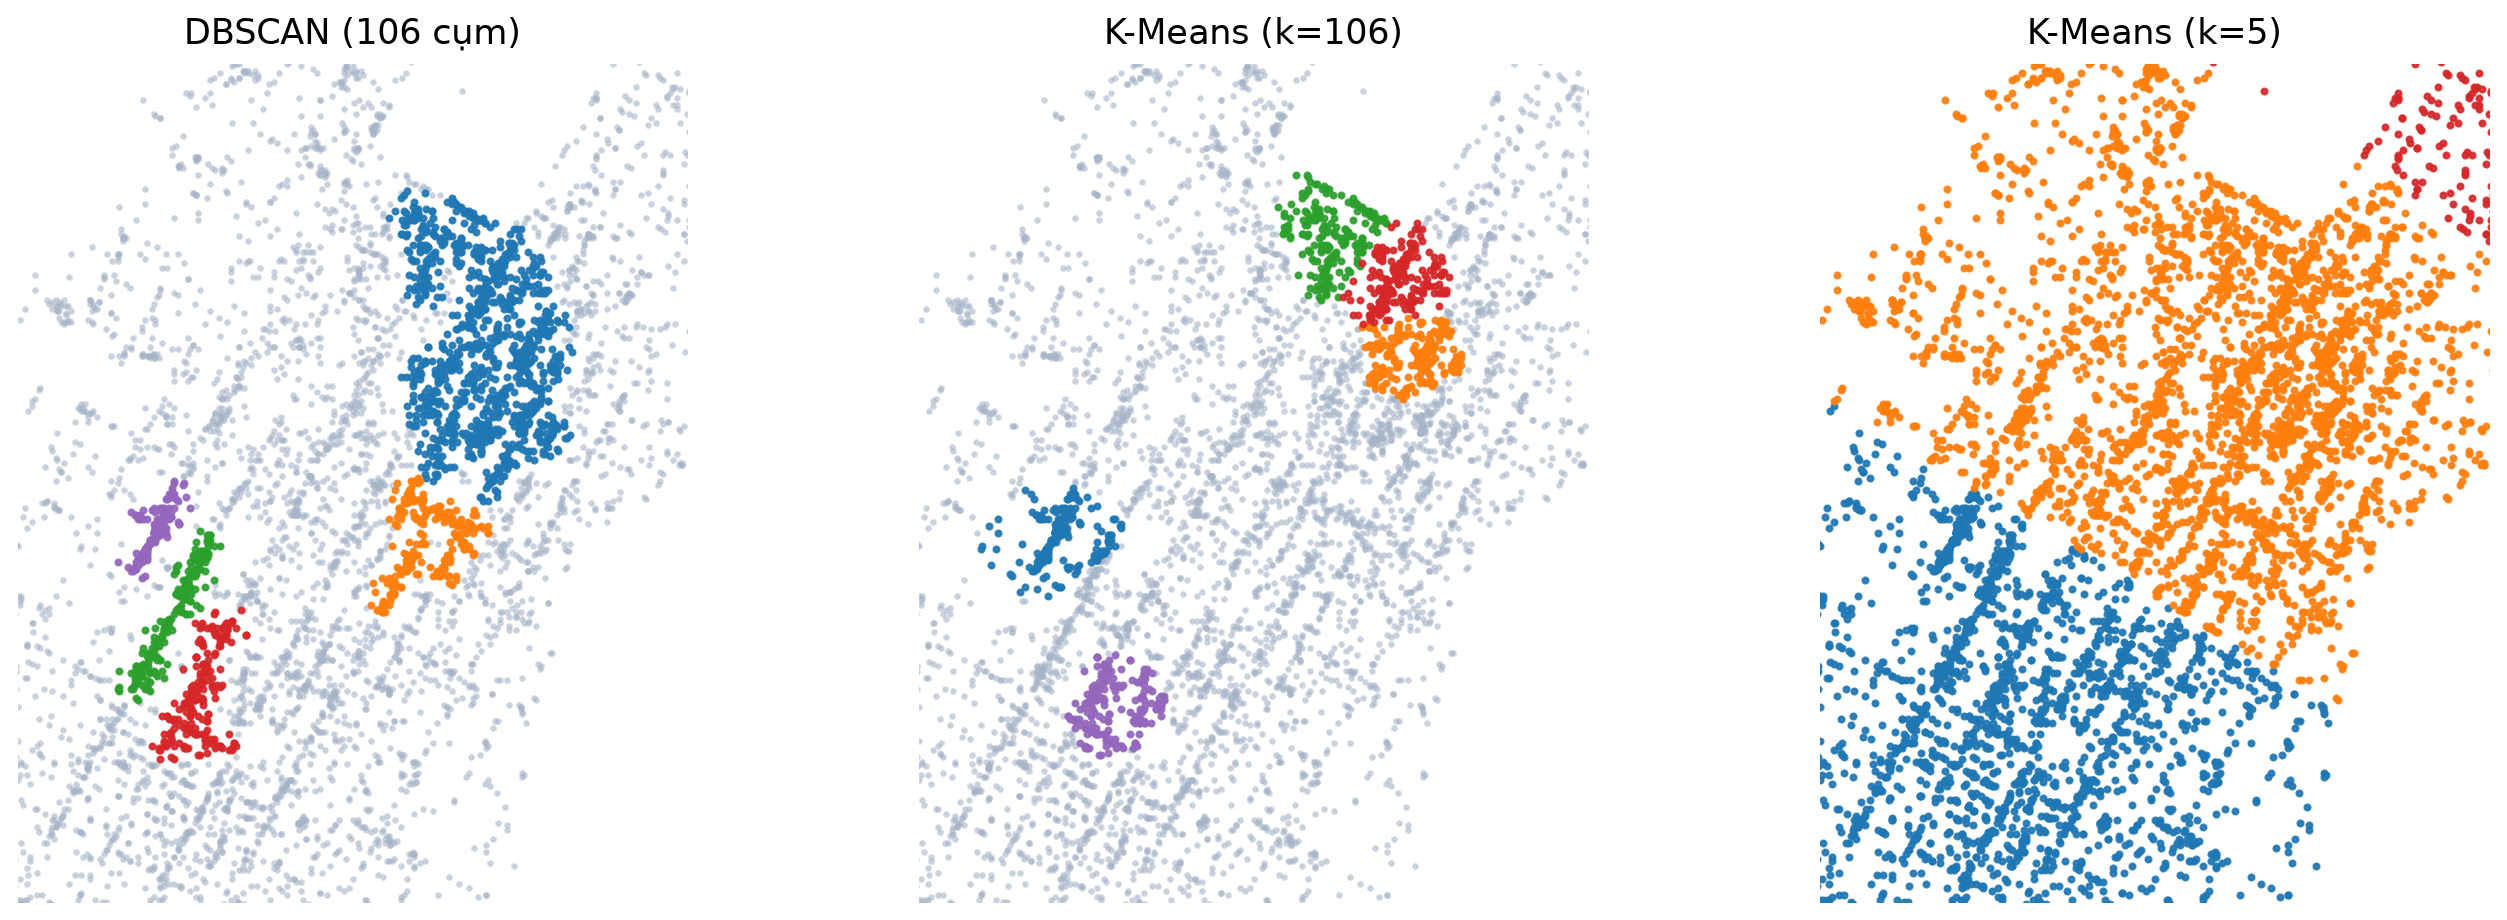

In [6]:
lon = filtered["longitude"].to_numpy()
lat = filtered["latitude"].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=180, constrained_layout=True)
colors = plt.get_cmap("tab10").colors

for ax, (title, labels) in zip(axes, [
    (f"DBSCAN ({n_db} cụm)", db_labels),
    (f"K-Means (k={n_db})", km_matched_labels),
    (f"K-Means (k={km_five.n_clusters})", km_five_labels),
]):
    counts = pd.Series(labels[labels >= 0]).value_counts()
    top_ids = counts.head(5).index.tolist()
    ax.scatter(lon, lat, s=3, c="#a6b4c8", alpha=0.45, rasterized=True)
    for rank, cluster_id in enumerate(top_ids):
        selected = labels == cluster_id
        ax.scatter(lon[selected], lat[selected], s=5, color=colors[rank], alpha=0.85, rasterized=True)
    ax.set_xlim(-74.002, -73.963)
    ax.set_ylim(40.735, 40.772)
    ax.set_aspect(1 / np.cos(np.deg2rad(float(lat.mean()))))
    ax.set_title(title, fontsize=14, pad=8)
    ax.set_axis_off()
plt.show()

## 6. Kết luận cần đọc từ kết quả vừa chạy

- **DBSCAN** cho biết nơi nào có đủ lượt đón gần nhau theo bán kính 70 m và 15 điểm tối thiểu; phần còn lại là nhiễu. Điều này phù hợp với câu hỏi của ứng dụng: tìm khu vực tập trung trong một ngày và khung giờ cụ thể.
- **K-Means** tạo đúng `k` vùng và gán mọi lượt đón, kể cả các điểm DBSCAN xem là nhiễu. Nó hữu ích khi cần chia **toàn bộ** lượt đón thành một số vùng cố định để tổng hợp, nhưng bản thân việc thuộc vùng K-Means không chứng minh nơi đó đủ dày để gọi là khu vực đón nổi bật.
- K-Means tối ưu độ gần với tâm cụm, còn DBSCAN tìm các vùng liên thông theo mật độ; số cụm bằng nhau **không** làm hai kết quả có cùng ý nghĩa. Hình dạng cụm, tỷ lệ nhiễu và kích thước cụm cần được xem cùng nhau. Không diễn giải bất kỳ kết quả nào thành dự báo có khách đang chờ.

Có thể sửa các hằng số ở cell đầu để thử Brooklyn hoặc một khung giờ khác. Nếu `n_db < 2`, notebook yêu cầu chọn ngữ cảnh khác thay vì gán bừa một `k` để so sánh.